In [8]:
import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from flowjax.distributions import Transformed, Uniform, Normal
from flowjax.bijections import RationalQuadraticSpline, Chain

Generated 20000 fixed samples.
Clean samples (first 5): [-0.41653156  0.21174534 -0.99702513  0.1849224  -0.3740796 ]
Noisy samples (first 5): [-0.20037831  0.50537723 -1.5678623  -0.00197713 -0.4736305 ]



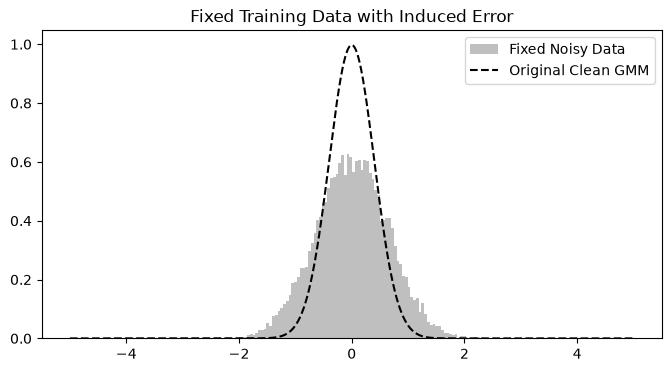

Generated 10000 fixed samples.
Clean samples (first 5): [-0.41653156  0.21174534 -0.99702513  0.1849224  -0.3740796 ]
Noisy samples (first 5): [-0.4122085   0.21761797 -1.0084419   0.18118441 -0.37607062]



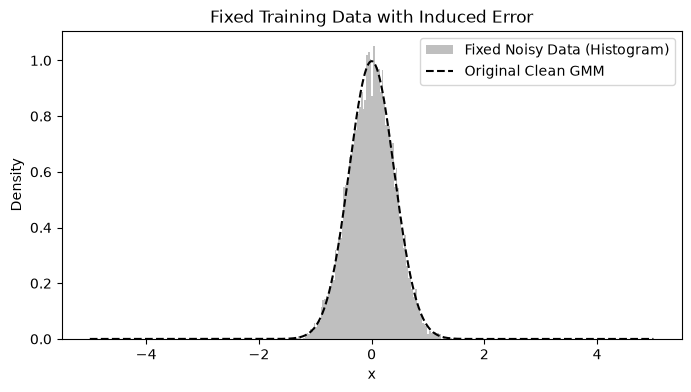

Training starting on the fixed noisy dataset...
Epoch    0 | Loss: 1.7397
Epoch  200 | Loss: 0.5107
Epoch  400 | Loss: 0.5052
Epoch  600 | Loss: 0.5041
Epoch  800 | Loss: 0.5037
Epoch 1000 | Loss: 0.5034
Epoch 1200 | Loss: 0.5032
Epoch 1400 | Loss: 0.5030
Epoch 1600 | Loss: 0.5029
Epoch 1800 | Loss: 0.5028
Epoch 1999 | Loss: 0.5028


In [ ]:


# ==========================================
# 1. Define the Target Distribution (3-Mode GMM)
# ==========================================
def sample_gmm(key, num_samples):
    """Samples from a Gaussian Mixture Model."""
    k1, k2 = jr.split(key)
    means = jnp.array([-3.0, 0.0, 3.0])
    stds = jnp.array([0.5, 0.4, 0.5])
    
    # We define the weights here. 
    # Try [0.1, 0.8, 0.1] to have a huge middle peak and tiny side peaks!
    weights = jnp.array([0.0, 1.0, 0.0]) 
    
    # Pass the weights as probabilities (p=weights) to the random choice
    components = jr.choice(k1, 3, shape=(num_samples,), p=weights)
    normals = jr.normal(k2, shape=(num_samples,))
    
    return means[components] + stds[components] * normals

def gmm_pdf(x):
    """Exact PDF of the target GMM for plotting."""
    means = jnp.array([-3.0, 0.0, 3.0])
    stds = jnp.array([0.5, 0.4, 0.5])
    
    # Keep the exact same weights here
    weights = jnp.array([0.0, 1.0, 0.0])
    
    pdf = jnp.zeros_like(x)
    for w, m, s in zip(weights, means, stds):
        pdf += w * jnp.exp(-0.5 * ((x - m) / s)**2) / (s * jnp.sqrt(2 * jnp.pi))
    return pdf


bound = 5.0 

base_dist = Normal(loc = 0, scale =  jnp.sqrt(bound))

# Create two layers, with only 5 knots per layer. 
# Total parameters are fewer, but chaining them makes them highly expressive!
spline_layer_1 = RationalQuadraticSpline(knots=8, interval=bound)
spline_layer_2 = RationalQuadraticSpline(knots=8, interval=bound)

# Chain them together sequentially: x -> layer_1 -> layer_2 -> y
bijection = Chain([spline_layer_1, spline_layer_2])

# Combine into a Normalizing Flow
flow = Transformed(base_dist, bijection)


@eqx.filter_value_and_grad
def loss_fn(model, x):
    log_probs = jax.vmap(model.log_prob)(x)
    return -jnp.mean(log_probs)

@eqx.filter_jit
def train_step(model, opt_state, x):
    loss, grads = loss_fn(model, x)
    updates, opt_state = optim.update(grads, opt_state)
    model = eqx.apply_updates(model, updates)
    return model, opt_state, loss

# Set up Optax Adam optimizer
learning_rate = 0.01
optim = optax.adam(learning_rate)
opt_state = optim.init(eqx.filter(flow, eqx.is_inexact_array))

# ==========================================
# 4. Create Fixed Dataset & Training Loop
# ==========================================
key = jr.PRNGKey(42)
key, sample_key, noise_key = jr.split(key, 3)

# 1. Generate ONE full fixed dataset
num_samples = 10000
x_train_clean = sample_gmm(sample_key, num_samples)

# 2. Induce error (Add Gaussian noise to the data)
# This will artificially widen the modes and add noise between them
noise_std = 0.01
noise = noise_std * jr.normal(noise_key, shape=x_train_clean.shape)
x_train = x_train_clean + noise

# 3. Print the samples
print(f"Generated {num_samples} fixed samples.")
print(f"Clean samples (first 5): {x_train_clean[:5]}")
print(f"Noisy samples (first 5): {x_train[:5]}\n")

# --- Visualize the induced error before training ---
plt.figure(figsize=(8, 4))
plt.hist(x_train, bins=100, density=True, alpha=0.5, color='gray', label="Fixed Noisy Data (Histogram)")

# For comparison, plot the original pure PDF
x_plot = jnp.linspace(-bound, bound, 1000)
plt.plot(x_plot, gmm_pdf(x_plot), 'k--', label="Original Clean GMM")
plt.title("Fixed Training Data with Induced Error")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()
# --------------------------------------------------

# 4. Training Loop
epochs = 2000

print("Training starting on the fixed noisy dataset...")
for epoch in range(epochs):
    # Pass the exact same dataset (x_train) every epoch
    flow, opt_state, loss = train_step(flow, opt_state, x_train)
    
    if epoch % 200 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:4d} | Loss: {loss:.4f}")

In [ ]:
from paramax import unwrap

# ==========================================
# 5. Study and Visualization (Direct Attribute Access)
# ==========================================
x_eval = jnp.linspace(-bound, bound, 1000)

learned_log_prob = jax.vmap(flow.log_prob)(x_eval)
learned_pdf = jnp.exp(learned_log_prob)
target_pdf = gmm_pdf(x_eval)

f_x = jax.vmap(flow.bijection.transform)(x_eval)
f_prime_x = jax.vmap(jax.grad(flow.bijection.transform))(x_eval)

# --- Extract the Learned Knots ---
unwrapped_bijection = unwrap(flow.bijection)

# Since we printed the tree, we know FlowJAX explicitly exposes 'x_pos'
# This array already contains the 10 coordinates (8 internal + 2 boundaries)
x_knots = unwrapped_bijection.x_pos

# Forward transform the X coordinates to get the Y coordinates (Target Space)
y_knots = jax.vmap(flow.bijection.transform)(x_knots)

# Get the derivatives at the knots
deriv_knots = jax.vmap(jax.grad(flow.bijection.transform))(x_knots)
# --------------------------------------------------------

# --- Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Densities
axes[0].plot(x_eval, target_pdf, 'k--', label="Target GMM", linewidth=2)
axes[0].plot(x_eval, learned_pdf, 'r-', label="Learned Flow Density", alpha=0.8, linewidth=2)
axes[0].vlines(y_knots, ymin=0, ymax=axes[0].get_ylim()[1], colors='blue', alpha=0.3, linestyles='dotted', label='Knot Boundaries')
axes[0].plot(y_knots, jnp.zeros_like(y_knots), 'bo', markersize=5) 
axes[0].set_title("Probability Densities")
axes[0].set_xlabel("x (Target Space)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Plot 2: The Spline Transformation (x -> y)
axes[1].plot(x_eval, f_x, 'b-', linewidth=2, label="Spline Curve")
axes[1].plot(x_knots, y_knots, 'ro', markersize=6, label="Learned Knots")
axes[1].set_title("Spline Forward Transform $f(x)$")
axes[1].set_xlabel("Base space (Uniform)")
axes[1].set_ylabel("Target space (GMM)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Plot 3: The Derivative (Proves how modes are made)
axes[2].plot(x_eval, f_prime_x, 'g-', linewidth=2, label="Derivative")
axes[2].plot(x_knots, deriv_knots, 'ro', markersize=6, label="Learned Knots")
axes[2].set_title("Derivative of Transform $f'(x)$")
axes[2].set_xlabel("Base space (Uniform)")
axes[2].set_ylabel("Derivative / Stretch factor")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

AttributeError: 'Chain' object has no attribute 'x_pos'

In [23]:

# ==========================================
# 5. Study and Visualization (Direct Attribute Access)
# ==========================================
x_eval = jnp.linspace(-bound, bound, 1000)

learned_log_prob = jax.vmap(flow.log_prob)(x_eval)
learned_pdf = jnp.exp(learned_log_prob)
target_pdf = gmm_pdf(x_eval)

f_x = jax.vmap(flow.bijection.transform)(x_eval)
f_prime_x = jax.vmap(jax.grad(flow.bijection.transform))(x_eval)

# --- Extract the Learned Knots ---
unwrapped_bijection = unwrap(flow.bijection)

# Since we printed the tree, we know FlowJAX explicitly exposes 'x_pos'
# This array already contains the 10 coordinates (8 internal + 2 boundaries)
x_knots = unwrapped_bijection.x_pos

# Forward transform the X coordinates to get the Y coordinates (Target Space)
y_knots = jax.vmap(flow.bijection.transform)(x_knots)

# Get the derivatives at the knots
deriv_knots = jax.vmap(jax.grad(flow.bijection.transform))(x_knots)
# --------------------------------------------------------

# --- Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Densities
axes[0].plot(x_eval, target_pdf, 'k--', label="Target GMM", linewidth=2)
axes[0].plot(x_eval, learned_pdf, 'r-', label="Learned Flow Density", alpha=0.8, linewidth=2)
axes[0].vlines(y_knots, ymin=0, ymax=axes[0].get_ylim()[1], colors='blue', alpha=0.3, linestyles='dotted', label='Knot Boundaries')
axes[0].plot(y_knots, jnp.zeros_like(y_knots), 'bo', markersize=5) 
axes[0].set_title("Probability Densities")
axes[0].set_xlabel("x (Target Space)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Plot 2: The Spline Transformation (x -> y)
axes[1].plot(x_eval, f_x, 'b-', linewidth=2, label="Spline Curve")
axes[1].plot(x_knots, y_knots, 'ro', markersize=6, label="Learned Knots")
axes[1].set_title("Spline Forward Transform $f(x)$")
axes[1].set_xlabel("Base space (Uniform)")
axes[1].set_ylabel("Target space (GMM)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Plot 3: The Derivative (Proves how modes are made)
axes[2].plot(x_eval, f_prime_x, 'g-', linewidth=2, label="Derivative")
axes[2].plot(x_knots, deriv_knots, 'ro', markersize=6, label="Learned Knots")
axes[2].set_title("Derivative of Transform $f'(x)$")
axes[2].set_xlabel("Base space (Uniform)")
axes[2].set_ylabel("Derivative / Stretch factor")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

AttributeError: 'Chain' object has no attribute 'x_pos'

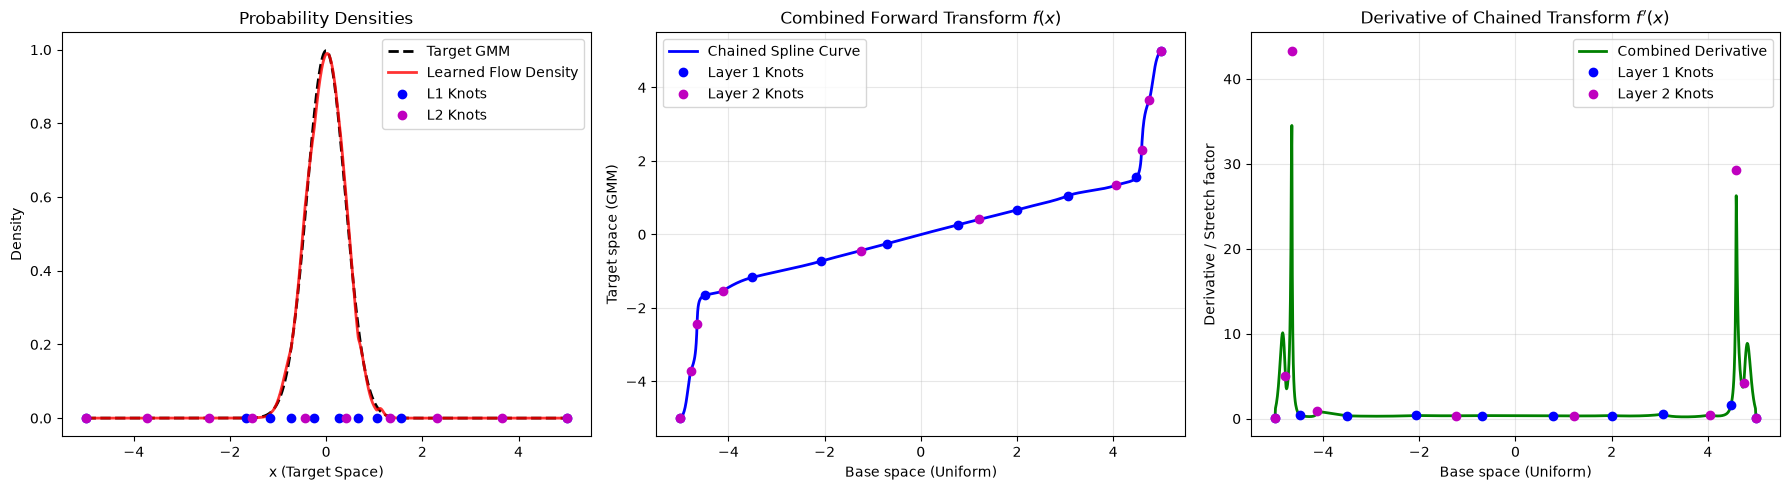

In [24]:
from paramax import unwrap

# ==========================================
# 5. Study and Visualization (Double Layer)
# ==========================================
x_eval = jnp.linspace(-bound, bound, 1000)

learned_log_prob = jax.vmap(flow.log_prob)(x_eval)
learned_pdf = jnp.exp(learned_log_prob)
target_pdf = gmm_pdf(x_eval)

# Thanks to JAX, we can still just call jax.grad on the entire chained transformation!
f_x = jax.vmap(flow.bijection.transform)(x_eval)
f_prime_x = jax.vmap(jax.grad(flow.bijection.transform))(x_eval)

# --- Extract the Learned Knots for BOTH layers ---
unwrapped_bijection = unwrap(flow.bijection)

# 1. Layer 1 knots (These exist in the base X space)
x_knots_L1 = unwrapped_bijection.bijections[0].x_pos
y_knots_L1 = jax.vmap(flow.bijection.transform)(x_knots_L1)
deriv_knots_L1 = jax.vmap(jax.grad(flow.bijection.transform))(x_knots_L1)

# 2. Layer 2 knots (These exist in the intermediate Z space)
z_knots_L2 = unwrapped_bijection.bijections[1].x_pos
# To plot them on the same X-axis, we must run them backwards through Layer 1
x_knots_L2 = jax.vmap(unwrapped_bijection.bijections[0].inverse)(z_knots_L2)
y_knots_L2 = jax.vmap(flow.bijection.transform)(x_knots_L2)
deriv_knots_L2 = jax.vmap(jax.grad(flow.bijection.transform))(x_knots_L2)
# --------------------------------------------------------

# --- Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Densities
axes[0].plot(x_eval, target_pdf, 'k--', label="Target GMM", linewidth=2)
axes[0].plot(x_eval, learned_pdf, 'r-', label="Learned Flow Density", alpha=0.8, linewidth=2)
# Mark where Layer 1 and Layer 2 placed their knots in the target space
axes[0].plot(y_knots_L1, jnp.zeros_like(y_knots_L1), 'bo', markersize=6, label='L1 Knots') 
axes[0].plot(y_knots_L2, jnp.zeros_like(y_knots_L2), 'mo', markersize=6, label='L2 Knots') 
axes[0].set_title("Probability Densities")
axes[0].set_xlabel("x (Target Space)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Plot 2: The Spline Transformation (x -> y)
axes[1].plot(x_eval, f_x, 'b-', linewidth=2, label="Chained Spline Curve")
axes[1].plot(x_knots_L1, y_knots_L1, 'bo', markersize=6, label="Layer 1 Knots")
axes[1].plot(x_knots_L2, y_knots_L2, 'mo', markersize=6, label="Layer 2 Knots")
axes[1].set_title("Combined Forward Transform $f(x)$")
axes[1].set_xlabel("Base space (Uniform)")
axes[1].set_ylabel("Target space (GMM)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Plot 3: The Derivative
axes[2].plot(x_eval, f_prime_x, 'g-', linewidth=2, label="Combined Derivative")
axes[2].plot(x_knots_L1, deriv_knots_L1, 'bo', markersize=6, label="Layer 1 Knots")
axes[2].plot(x_knots_L2, deriv_knots_L2, 'mo', markersize=6, label="Layer 2 Knots")
axes[2].set_title("Derivative of Chained Transform $f'(x)$")
axes[2].set_xlabel("Base space (Uniform)")
axes[2].set_ylabel("Derivative / Stretch factor")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()